<h2>
  Vignette 03: Simple access to raw data for analysis (the `DataPort`)<br>
  <span style="font-size: 12px; font-weight: normal; display: block">
    <i>"There was a line, there was a formula, sharp as a knife" -- Talking Heads</i><br>
  </span>
</h2>

The ViewPort provides you with a quick and unified way to view your data: all types of data efficiently rendered at screen resolution, as it handles scaling, flips, rotation, and brightness/contrast.  For analysis of images and 'omic data, however, we want to ensure that we are viewing raw data, not resampled or blurred data that might bias the analysis.  This is where the partner of the Viewport shines: the `DataPort`. The `DataPort` grabs the raw data from your ROI (a View, or an ROI from an ROIChannel) for analysis. 

In [1]:
%load_ext autoreload
%autoreload 2

# SPACKLE imports
from spackle.io_utils import load_sample 
from pathlib import Path

# UPDATE THIS TO YOUR LOCAL FOLDER PATH (pointing to the directory)
save_path = Path.home() / 'spackle_data' / 'VisiumSample'

# Load the sample! (Notice how fast this is, even with massive images)
# With verbose=True, SPACKLE will automatically print the inventory of what was loaded.
sample = load_sample(save_path, verbose=True)

# Delete thd 2um binset if the 4um is present -- 2um is just artifact anyways
if '2um' in sample.images and '4um' in sample.images:
    del sample.images['2um']



  - Images available: 'dapi' (16g), 'detected' (24c), 'hires' (24c), 'lowres' (24c), 'neun' (16g)
  - Image channels loaded: dapi, detected, hires, lowres, neun
  - Omic channels loaded: spots
  - Cell channels loaded: 
  - ROIs loaded: 


#### What this vignette covers

The `DataPort` is the analytical counterpart to the `ViewPort`. Where the ViewPort renders data at screen resolution for display, the DataPort extracts the same region in its **native format** — full uint16 images, raw AnnData — with no resampling or colorization unless you ask for it.

1. Use a ViewPort to define a cortical region visually
2. Hand that region to a DataPort in one line
3. Extract the NeuN channel and run Cellpose nuclear segmentation
4. Convert segmentation into a spatially-registered ROIChannel
5. Extract omic data and plot a Cux1 depth profile (upper-layer density by cortical depth)

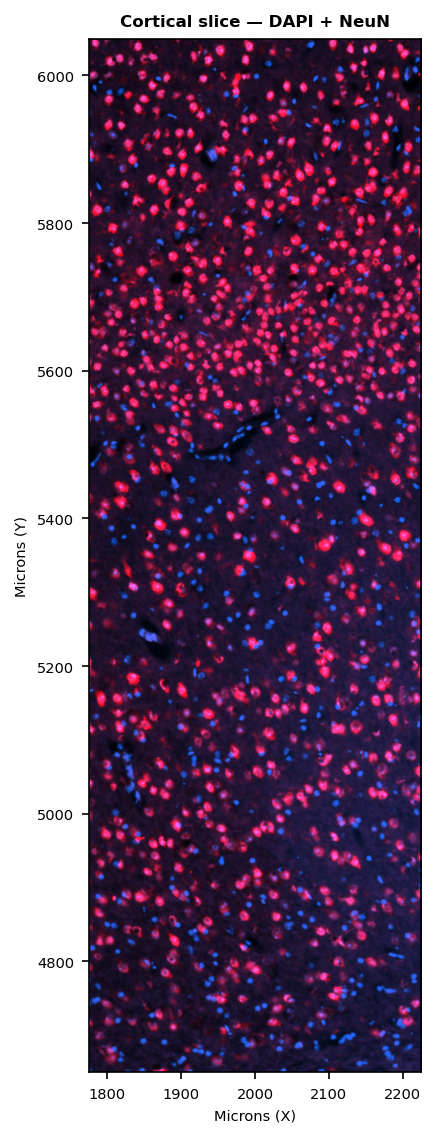

In [2]:
import numpy as np
from spackle.plot_utils import plot_image_grid

# Define a cortical region of interest
vp = sample.viewport(center_um=(2000, 5350), fov_um=(450, 1400))
vp.add_layer(sample.images['dapi']).adjust_layer(
    tint='xkcd:bright blue', gamma=1.2, percentile_clip=(5, 99), blend_mode='lighten')
vp.add_layer(sample.images['neun']).adjust_layer(
    tint='xkcd:bright red',  gamma=0.8, percentile_clip=(5, 99), blend_mode='lighten')
vp.update_view(flip_y=True)

cortex_view = vp.render()
plot_image_grid(cortex_view, titles=['Cortical slice — DAPI + NeuN'], width=3, font_size='small');


#### Handing off to the DataPort

`DataPort.from_viewport(vp)` clones the ViewPort's spatial state — same ROI, same coordinate frame — but loads nothing yet. Data is only materialized when you call `extract()` or `crop_channel()`, and only for the requested region.

In [3]:
from spackle.dataport import DataPort

dp = DataPort.from_viewport(vp)
print(f'DataPort ROI: {dp.roi_extent}')

# Extract NeuN downsampled to 0.5 um/px — keeps nuclei at ~16-20 px diameter for Cellpose
neun_arr = dp.extract(sample.images['neun'], downsample_mpp=0.5)
print(f'Extracted: {neun_arr.shape}  dtype={neun_arr.dtype}')


DataPort ROI: (1775.0, 2225.0, 4650.0, 6050.0)
Extracted: (2800, 900)  dtype=uint16


#### Cell segmentation with Cellpose

Spackle is designed to be a lightweight framework that focuses on the spatial, and let other packages handle the analysis.  In this example, we're going to select an ROI, and run a cell segmentation package (Cellpose) via the Datport.  
- We've already selected an ROI (in this case the FOV) for analysis above.  
- Next, we select and configure the cell segmentation model via `model = models.CellposeModel()`.  
- Finally, we configure the dataport by selecting the layer (sample), select any options (in this case downsampling to 2um per pixel, which is sufficient for NeuN images), and we tell the dataport to use our selected function (fn=lambda arr: model...).  

The dataport hands the data off to our pre-configured function, and passes back all the info needed to convert the results back to micron space. Notice that we hand the **function** to the DataPort -- the DataPort knows nothing about CellPose, and if you want to use StarDist or another segmentation algorithm it's no problem! 

pretrained model C:\Users\maynard\.cellpose\models\cpsam not found, using default model


Segmented 784 nuclei
Converted 784 contours to micron ROIs


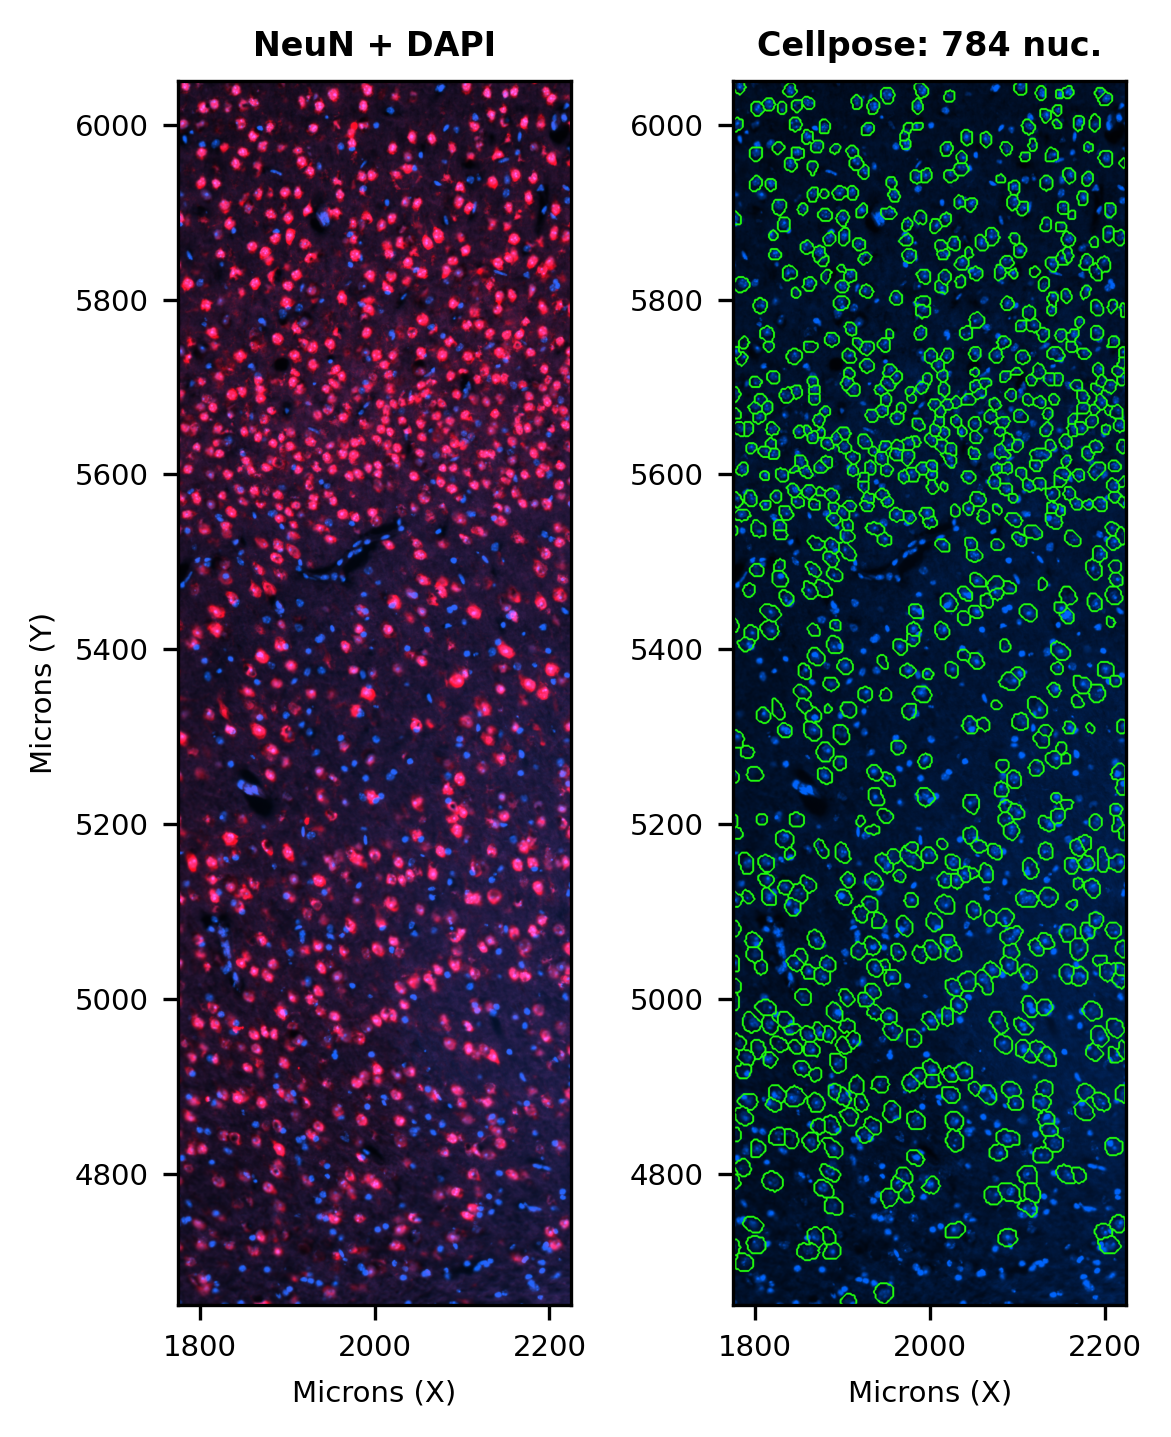

In [4]:
import warnings
from cellpose import models

# Suppress a PyTorch-internal sparse tensor warning emitted by Cellpose internals
warnings.filterwarnings('ignore', message='Sparse invariant checks')

# Set up Cellpose with model we want to use for segmentation
model = models.CellposeModel(gpu=True, pretrained_model='nuclei')

# Pass Cellpose as a function to DataPort — DataPort handles extraction and spatial bookkeeping.
# To switch to tiling later: just add tile_size_um=500 and it works identically per tile.
results = dp.process(
    sample.images['neun'],
    fn=lambda arr: model.eval(arr, diameter=None)[0],  # channels= removed (deprecated in Cellpose v4.0.1+)
    downsample_mpp=2   # reduce resolution for macbook testing; remove for full res segementation on PC with GPU
)
extent_um, masks = results[0]    #<-- extent_um tells DataPort how to convert back; the rest is CellPose's output
print(f'Segmented {masks.max()} nuclei')

# Convert to micron-space ROIs — extent_um + masks.shape encode the pixel scale automatically
nuclei_rois = (DataPort.mask_to_roi_channel(masks, extent_um, name='nuclei', prefix='cell')
               .set_style(line_color='xkcd:electric green', line_width=4, fill=False))
print(f'Converted {len(nuclei_rois.polygons)} contours to micron ROIs')

# Make a viewport then display the cortex view alongside the StarDist segmentation viewseg_view = vp.clone()
seg_view = vp.clone()
seg_view.add_layer(nuclei_rois)
seg_view.adjust_layer(name='neun', visible=False)
plot_image_grid(
    [cortex_view, seg_view.render()],
    titles=['NeuN + DAPI', f'Cellpose: {len(nuclei_rois.polygons)} nuc.'],
    width=4, font_size='small', dpi=300
);

#### Alternative segmentation: StarDist

Swapping in a different segmentation algorithm requires changing exactly two lines — the model setup and the lambda passed to `dp.process()`. Everything downstream (DataPort bookkeeping, `mask_to_roi_channel`, visualization) is identical. StarDist is a similar segmentation algorithm that also works well out of the box.  But if you wanted to use a different image analysis package, dataport just hands it an the raw image data it needs, and is ready to convert it back when it's done.

<i>-- Techical note: Windows requires developer mode to be 'on' for Stardist to access it's model library <br>
-- In Win 11, go to: Settings->System->For Developers->Developer mode ON (requires admin acct)  </i>

Found model '2D_versatile_fluo' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.
Segmented 619 nuclei
Converted 619 contours to micron ROIs


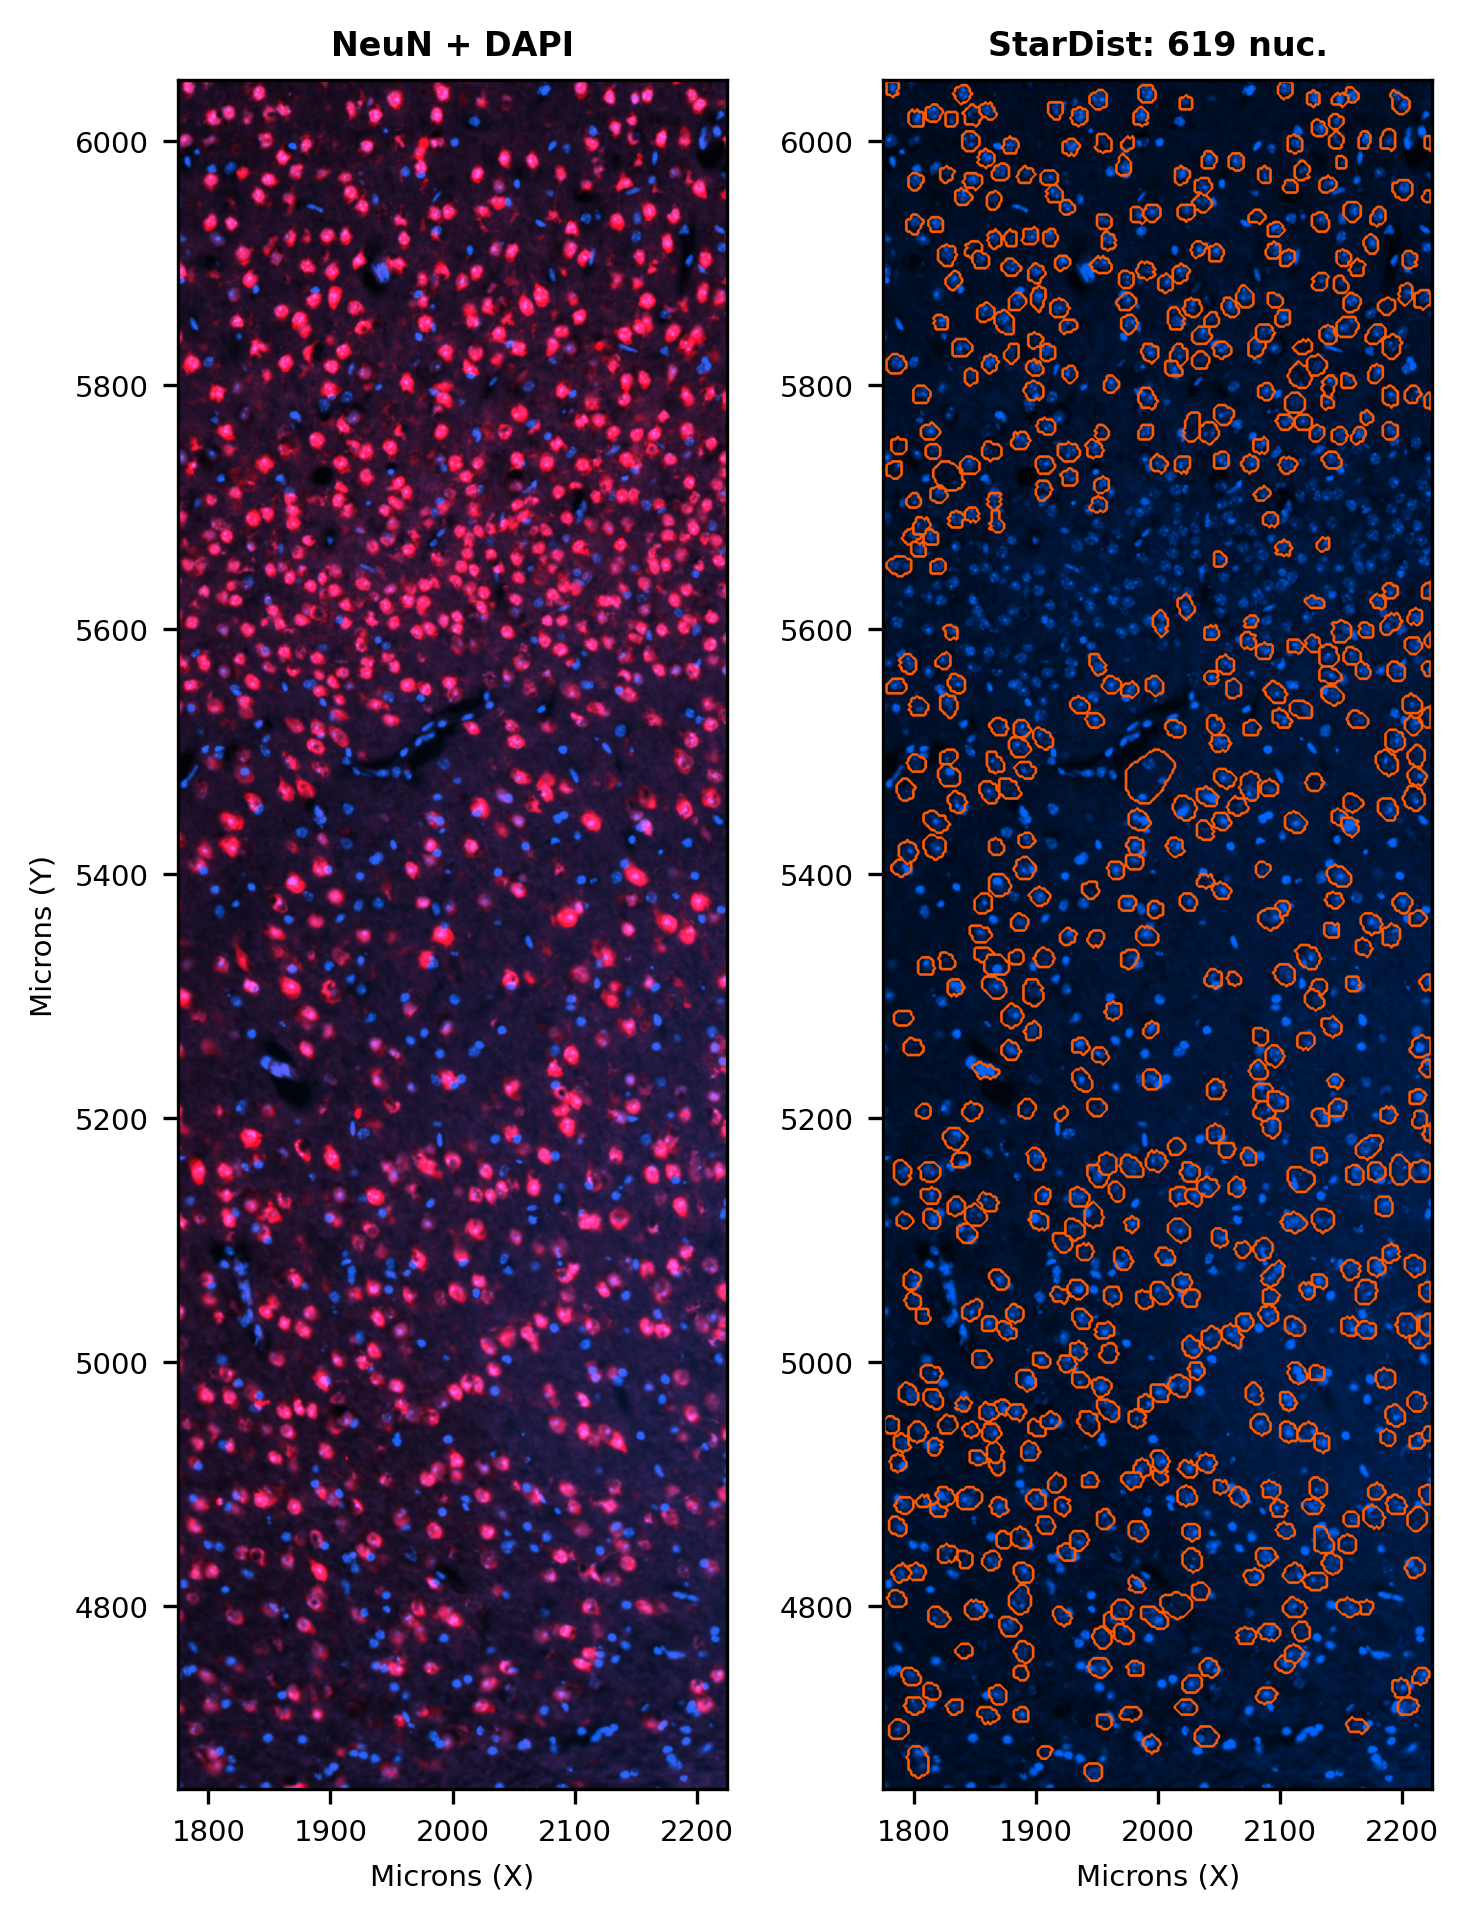

In [5]:
from stardist.models import StarDist2D
from csbdeep.utils import normalize

# Load the pre-trained fluorescence model -- no training data needed
model = StarDist2D.from_pretrained('2D_versatile_fluo')        # <-- Change 1: Swap CellPose for StarDist

# Same dp.process() call -- only the fn= lambda changes
results = dp.process(
    sample.images['neun'],
    fn=lambda arr: model.predict_instances(normalize(arr))[0],  # <-- Change 2: Swap the function to StarDist
    downsample_mpp=2
)
extent_um, masks = results[0]    #<-- extent_um tells DataPort how to convert back; the rest is StarDist's output
print(f'Segmented {masks.max()} nuclei')

# Everything below is identical to the Cellpose version
stardist_rois = (DataPort.mask_to_roi_channel(masks, extent_um, name='nuclei_sd', prefix='cell')
                 .set_style(line_color='xkcd:bright orange', line_width=4, fill=False))
print(f'Converted {len(stardist_rois.polygons)} contours to micron ROIs')

# Make a viewport then display the cortex view alongside the StarDist segmentation view
seg_view_sd = vp.clone()
seg_view_sd.add_layer(stardist_rois)
seg_view_sd.adjust_layer(name='neun', visible=False)
plot_image_grid(
    [cortex_view, seg_view_sd.render()],
    titles=['NeuN + DAPI', f'StarDist: {len(stardist_rois.polygons)} nuc.'],
    width=5, font_size='small', dpi=300
);

#### The DataPort keeps your analysis grounded in real space

In this example, you may have noticed a few key things:

- **SPACKLE doesn't care what algorithm you use.** The DataPort hands raw pixel data to whatever function you give it — CellPose, StarDist, or anything else. Swapping algorithms required exactly two line changes. The coordinate bookkeeping is handled automatically either way.
- **Results come back in micron space, not pixel space.** When the segmentation returns a mask, the DataPort already knows where that mask lives in the real world. You don't have to track scale factors or offsets to convert cell centroids back to tissue coordinates.
- **Only the data you need is loaded.** The DataPort extracts just the pixels in your ROI at the resolution you need — it doesn't touch the rest of the image. This keeps memory usage low even when working with very large tissue sections.

Next: The same ViewPort and DataPort tools work identically regardless of which spatial platform your data came from. In the next section, we'll load a Xenium dataset — a different platform with a very different raw data format — and show that the workflow looks nearly identical.